In [16]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import resample_poly
from pathlib import Path

In [10]:
#生成5kHz信号
high_sr = 48000  #用高采样率表示模拟信号
target_sr = 8000
duration = 1
t = np.arange(high_sr * duration) / high_sr
f = 5000    #信号频率

sine = np.sin(2*np.pi * f * t)

In [11]:
#直接8kHz采样
sine_alias = sine[::6]

In [22]:
#FFT分析
def get_fft(x, sr):
    n = len(x)
    fft_result = np.fft.rfft(x)

    freq = np.fft.rfftfreq(n,1/sr)

    magnitude = np.abs(fft_result) / n

    return freq,magnitude

In [20]:
resampled_signal = resample_poly(
    sine,target_sr,high_sr
)

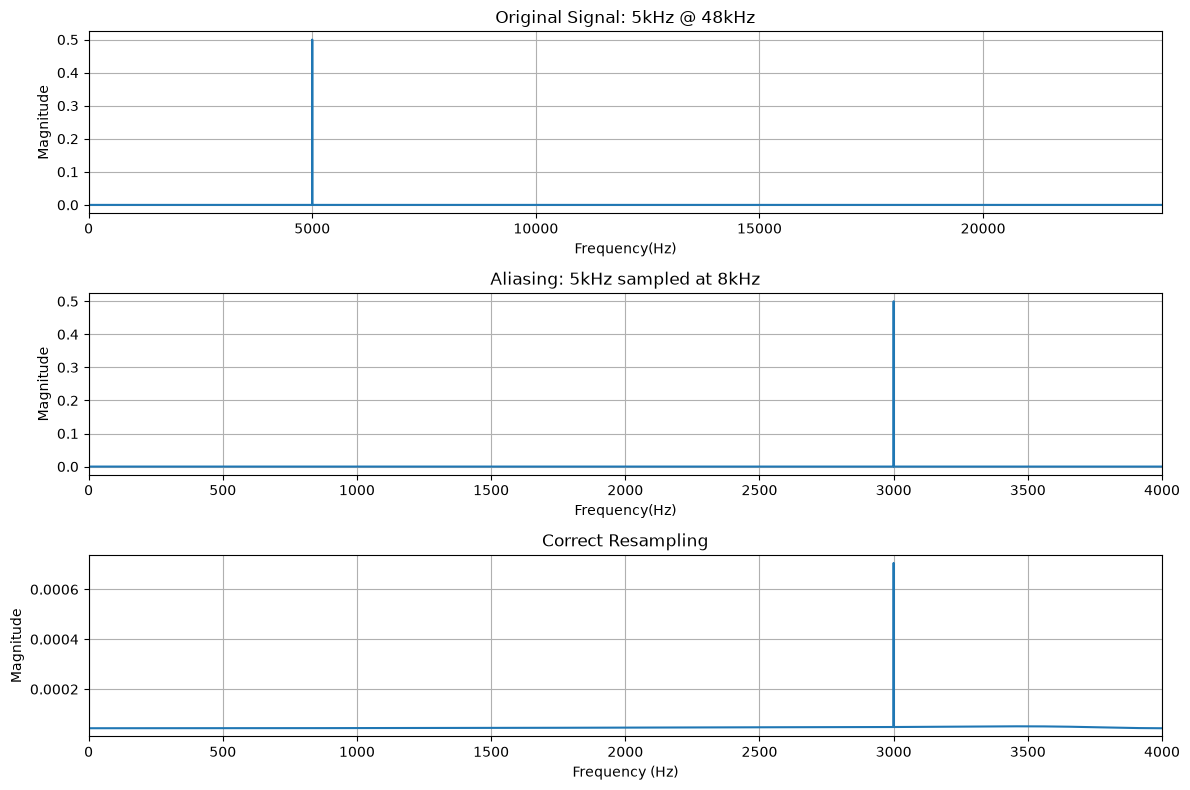

In [ ]:
#对照图
plt.figure(figsize=(12,8))

# =====================
# 1. 原始48kHz信号
# =====================
freq1,mag1 = get_fft(sine,high_sr)
plt.subplot(3,1,1)
plt.plot(freq1,mag1)
plt.title("Original Signal: 5kHz @ 48kHz")
plt.xlabel("Frequency(Hz)")
plt.ylabel("Magnitude")
plt.xlim(0,high_sr/2)
plt.grid()

# =====================
# 2. 直接8kHz采样
# =====================
freq2,mag2 = get_fft(sine_alias,target_sr)
plt.subplot(3,1,2)
plt.plot(freq2,mag2)
plt.title("Aliasing: 5kHz sampled at 8kHz")
plt.xlabel("Frequency(Hz)")
plt.ylabel("Magnitude")
plt.xlim(0,target_sr/2)
plt.grid()

# =====================
# 3. 正确resample
# =====================

freq3, mag3 = get_fft(
    resampled_signal,
    target_sr
)

plt.subplot(3,1,3)

plt.plot(freq3, mag3)

plt.title(
    "Correct Resampling"
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")

plt.xlim(0, target_sr/2)

plt.grid()


plt.tight_layout()

#保存
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)
plt.savefig(
    FIGURE_DIR / "aliasing_comparsion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()